# Guardian Lab — Logistic Regression URL/QR v3

Satu keluarga classifier: **Logistic Regression**. V2 menaikkan accuracy benchmark Phresh domain baru dari 80,48% ke 82,63%, tetapi FPR naik ke 1,13% dan generalisasi sumber turun. Karena itu **v2 tidak dipromosikan**.

V3 memperluas data pengembangan dengan sumber yang sudah pernah dievaluasi. PhiUSIIL, Mendeley2020, dan PhishVN gold/silver sekarang menjadi **sumber pengembangan**, bukan lagi test independen. Semua domain dipisahkan untuk fit/tune/calibration/threshold/group holdout. Satu sumber tambahan URL-Phish dipin sebagai challenge eksternal baru dan tidak dipakai tuning.

Phresh test asli tetap di luar fit. Model, kalibrator, dan threshold dibekukan sebelum evaluasi. Accuracy, balanced accuracy, recall, FPR, ukuran kelas, dan ketidakpastian harus dibaca bersama. Tidak ada klaim produksi atau gold set Indonesia.


## 1. Lingkungan dan cara menjalankan

Gunakan **Python 3.12**, lalu jalankan sel berurutan dengan **Run All**. Di VS Code pilih interpreter `ml/.venv`; Jupyter dapat memakai environment Python 3.12 dengan dependency berikut:

```bash
python -m pip install numpy==2.4.3 pandas==2.2.3 pyarrow==22.0.0 requests==2.32.3 scikit-learn==1.8.0 scipy==1.16.3 tldextract==5.3.0 joblib==1.5.3 matplotlib==3.10.8 threadpoolctl==3.6.0 ipykernel
```

Simpan notebook dengan nama `guardian_lab_url_qr.ipynb`. Cache tersanitasi yang sudah diaudit digunakan bila tersedia. Pada salinan mandiri tanpa cache, notebook mengambil kolom URL/label/tanggal dari sumber resmi yang dipin; kolom HTML tidak diambil dan situs target tidak dikunjungi. Transfer dibatasi 80 MiB.

Hasil notebook masuk ke `ml/runs/notebook-tfidf-logistic-v3/`. Run yang sudah dibekukan akan **dimuat ulang**, bukan dilatih ulang berdasarkan hasil test. Ubah RUN_ID hanya untuk eksperimen yang memiliki protokol dan holdout yang sesuai.


In [1]:
import math
import time
import warnings
from scipy.sparse import csr_matrix, hstack
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.exceptions import ConvergenceWarning
import copy
import csv
import gc
import hashlib
import io
import json
import sys
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from zipfile import ZipFile

import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import requests
from IPython.display import Image, display
from requests.adapters import HTTPAdapter
from scipy.special import logit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from threadpoolctl import threadpool_limits
from urllib3.util.retry import Retry

assert sys.version_info[:2] == (3, 12), "Gunakan kernel Python 3.12."
REQUIRED = {
    "numpy": "2.4.3",
    "pandas": "2.2.3",
    "pyarrow": "22.0.0",
    "requests": "2.32.3",
    "scikit-learn": "1.8.0",
    "scipy": "1.16.3",
    "tldextract": "5.3.0",
    "joblib": "1.5.3",
    "matplotlib": "3.10.8",
    "threadpoolctl": "3.6.0",
}
VERSIONS = {name: version(name) for name in REQUIRED}
assert VERSIONS == REQUIRED, "Samakan versi dependency lalu restart kernel."

NOTEBOOK_NAME = "guardian_lab_url_qr.ipynb"
candidates = [
    Path.cwd() / NOTEBOOK_NAME,
    Path.cwd().parent / NOTEBOOK_NAME,
    Path.cwd().parent / "guardian_lab_ai" / NOTEBOOK_NAME,
]
NOTEBOOK_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
assert NOTEBOOK_PATH is not None, "Simpan notebook dan jalankan dari folder notebook."
ROOT = NOTEBOOK_PATH.parent
RUN_ID = "notebook-tfidf-logistic-v3"
assert __import__("re").fullmatch(r"[a-z0-9][a-z0-9_-]{0,47}", RUN_ID)
RUN = ROOT / "ml/runs" / RUN_ID
DATA, REPORTS, ARTIFACTS = RUN / "data", RUN / "reports", RUN / "artifacts"
for directory in (DATA, REPORTS, ARTIFACTS, RUN / "plots"):
    directory.mkdir(parents=True, exist_ok=True)

REVISION = "eca603e0ecd4f698f8d4d226c088659e72681239"
REPRESENTATION = "url-core-redacted-v1"
SEED = 20261101
CONFIG = {
    "classifier": "LogisticRegression",
    "solver": "liblinear",
    "seed": SEED,
    "views": ["scheme_free_char40k", "scheme_free_char100k_word20k_numeric"],
    "C_trials": [0.5, 2.0, 8.0],
    "max_iter": 300,
    "tol": 0.0001,
    "vocabulary_fit_limit": 150000,
    "vocabulary_source_cap": 60000,
    "char_min_df": 4,
    "word_max_features": 20000,
    "word_weight": 0.7,
    "numeric_weight": 0.2,
    "source_weights": "sqrt(max_source_fit_count/source_fit_count), mean-normalized",
    "source_group_split": [60, 75, 82, 90, 100],
    "selection": "macro_source_recall_then_min_source_recall_then_AP_under_global_source_FPR_cap",
    "calibration": "sigmoid",
    "calibration_C": 1000,
    "high_target_fpr": 0.001,
    "warning_target_fpr": 0.01,
    "source_revision": REVISION,
    "representation": REPRESENTATION,
    "exclude_scheme_from_all_model_features": True,
}
LEGACY_CONFIG = {
    "ngram_range": [3, 5],
    "max_features": 40000,
    "min_df": 4,
    "vocabulary_fit_limit": 100000,
    "alpha_trials": [1e-5, 1e-6],
    "max_epochs": 12,
    "batch_size": 16384,
    "patience": 3,
    "early_stopping_min_ap_gain": 0.0001,
    "average": True,
    "high_target_fpr": 0.001,
}
notebook_document = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
code_sources = [
    "".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"]
    for cell in notebook_document["cells"]
    if cell["cell_type"] == "code"
]
CODE_SHA256 = hashlib.sha256("\n\n".join(code_sources).encode()).hexdigest()
SPEC_SHA256 = hashlib.sha256(
    json.dumps({"config": CONFIG, "code": CODE_SHA256}, sort_keys=True).encode()
).hexdigest()


def clean_json(value):
    if isinstance(value, dict):
        return {str(k): clean_json(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [clean_json(v) for v in value]
    if isinstance(value, np.ndarray):
        return clean_json(value.tolist())
    if isinstance(value, np.generic):
        return clean_json(value.item())
    return value


def write_json(path, value):
    path.write_text(
        json.dumps(clean_json(value), indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
    )


display(pd.DataFrame({"package": VERSIONS.keys(), "version": VERSIONS.values()}))
print("Classifier: Logistic Regression, optimizer liblinear; seed:", SEED)

,package,version
0,numpy,2.4.3
1,pandas,2.2.3
2,pyarrow,22.0.0
3,requests,2.32.3
4,scikit-learn,1.8.0
5,scipy,1.16.3
6,tldextract,5.3.0
7,joblib,1.5.3
8,matplotlib,3.10.8
9,threadpoolctl,3.6.0


Classifier: Logistic Regression, optimizer liblinear; seed: 20261101


## 2. Representasi URL dan privasi

Query/fragment dibuang identik pada kedua kelas karena pengolahan sumber sangat timpang antar kelas. Model memakai skema, hostname, dan path yang sudah dinormalisasi serta disanitasi. Userinfo, IP privat, input rusak, dan kandidat informasi sensitif yang tidak dapat ditangani akan ditolak.

PSL berjalan **offline**, termasuk private suffix untuk membedakan tenant hosting. Regex screening tidak membuktikan semua PII sudah ditemukan. Tidak ada contoh URL dataset atau baris korban yang ditampilkan.


In [2]:
import hashlib
import ipaddress
import re
from dataclasses import dataclass
from functools import lru_cache
from urllib.parse import quote, unquote, urlsplit

import tldextract

EXTRACT = tldextract.TLDExtract(
    suffix_list_urls=(),
    cache_dir=None,
    include_psl_private_domains=True,
)
EMAIL = re.compile(r"[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}")
PHONE = re.compile(r"(?<!\w)(?:\+62|62|0)[ .-]?8[1-9](?:[ .-]?\d){6,10}\b")
NUMBER = re.compile(r"(?<!\d)(?:\d[ -]?){8,}(?!\d)")
TOKEN = re.compile(
    r"\d{9,10}:[\w-]{30,}|[a-fA-F0-9]{24,}|"
    r"[A-Za-z0-9_-]{24,}\.[A-Za-z0-9_-]{16,}(?:\.[A-Za-z0-9_-]+)?|"
    r"(?=[A-Za-z0-9_-]{24,}(?:\W|$))(?=[A-Za-z0-9_-]*\d)[A-Za-z0-9_-]{24,}"
)
SENSITIVE_KEY = re.compile(
    r"^(?:password|passwd|pwd|token|secret|otp|pin|session|authorization|"
    r"email|phone|mobile|nik|account|credential|access_token|api_key)$",
    re.I,
)
CONTROL = re.compile(r"[\x00-\x20\x7f\\]")
HOST_LABEL = re.compile(r"^[a-z0-9](?:[a-z0-9-]{0,61}[a-z0-9])?$", re.I)


class InvalidUrl(ValueError):
    """Only a fixed reason code; never include user input in the exception."""


@dataclass(frozen=True)
class PreparedUrl:
    core: str
    host: str
    path: str
    scheme: str
    group: str
    suffix: str
    redactions: int

    @property
    def digest(self) -> str:
        return hashlib.sha256(self.core.encode()).hexdigest()


@lru_cache(maxsize=100_000)
def domain_parts(host: str) -> tuple[str, str]:
    result = EXTRACT(host)
    return result.top_domain_under_public_suffix or host, result.suffix or "unknown"


def redact_path(path: str) -> tuple[str, int]:
    decoded = unquote(unquote(path))
    if CONTROL.search(decoded.replace(" ", "")):
        raise InvalidUrl("decoded_control_or_backslash")
    if re.search(r"%[0-9a-fA-F]{2}", decoded):
        raise InvalidUrl("ambiguous_nested_encoding")
    count = 0
    # A replacement can join surrounding token pieces into a new match.
    for _ in range(5):
        changed = 0
        for pattern in (EMAIL, PHONE, NUMBER, TOKEN):
            decoded, matches = pattern.subn("REDACTED", decoded)
            count += matches
            changed += matches
        if not changed:
            break
    segments = decoded.split("/")
    for index in range(1, len(segments)):
        if SENSITIVE_KEY.fullmatch(segments[index - 1]) and segments[index]:
            segments[index] = "REDACTED"
            count += 1
    # Fixed escaping avoids storing decoded data as a new query/fragment.
    encoded = quote("/".join(segments), safe="/-._~!$&'()*+,;=:@")
    if any(pattern.search(encoded) for pattern in (EMAIL, PHONE, NUMBER, TOKEN)):
        raise InvalidUrl("residual_sensitive_candidate")
    return encoded, count


def prepare_url(value: str) -> PreparedUrl:
    if not isinstance(value, str) or not value.strip():
        raise InvalidUrl("empty")
    value = value.strip()
    if len(value) > 16_384:
        raise InvalidUrl("too_long")
    if CONTROL.search(value):
        raise InvalidUrl("control_whitespace_or_backslash")
    if "://" not in value:
        if re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*:", value) and not re.match(
            r"^[^/:]+:\d+(?:/|$)",
            value,
        ):
            raise InvalidUrl("unsupported_scheme")
        value = "https://" + value
    try:
        parsed = urlsplit(value)
        scheme = parsed.scheme.lower()
        if scheme not in ("http", "https"):
            raise InvalidUrl("unsupported_scheme")
        if parsed.username is not None or parsed.password is not None:
            raise InvalidUrl("userinfo")
        host = (
            (parsed.hostname or "").rstrip(".").encode("idna").decode("ascii").lower()
        )
        port = parsed.port
    except (ValueError, UnicodeError):
        raise InvalidUrl("invalid_authority") from None
    if not host or len(host) > 253:
        raise InvalidUrl("invalid_host")
    try:
        address = ipaddress.ip_address(host)
    except ValueError:
        address = None
    if address is not None:
        if not address.is_global:
            raise InvalidUrl("non_public_ip")
    elif "." not in host or not all(
        HOST_LABEL.fullmatch(part) for part in host.split(".")
    ):
        raise InvalidUrl("invalid_or_local_host")
    elif host.endswith((".localhost", ".local", ".internal", ".test", ".invalid")):
        raise InvalidUrl("non_public_host")
    if PHONE.search(host) or NUMBER.search(host) or TOKEN.search(host):
        raise InvalidUrl("sensitive_host_candidate")
    group, suffix = domain_parts(host)
    if address is not None:
        group, suffix = host, "ip"
    authority = f"[{host}]" if ":" in host else host
    if port is not None and (scheme, port) not in (("http", 80), ("https", 443)):
        authority += f":{port}"
    path, count = redact_path(parsed.path or "/")
    return PreparedUrl(
        f"{scheme}://{authority}{path}", host, path, scheme, group, suffix, count
    )

## 3. Aset resmi dan ingestion

- [PhreshPhish](https://huggingface.co/datasets/phreshphish/phreshphish): fondasi training dan evaluasi temporal, revision dipin.
- [PhiUSIIL UCI](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset): pembanding eksternal, ZIP diverifikasi SHA-256.
- Label proyek: **benign = 0**, **phishing = 1**. Label sumber PhiUSIIL berlawanan: **0 sumber = phishing**.
- Keduanya mencantumkan CC BY 4.0; card PhreshPhish juga menyebut riset anti-phishing. Ketentuan sumber perlu diperiksa sebelum distribusi atau penggunaan lain.

Sel berikut hanya mendefinisikan pembacaan dataset. Jika cache ada, tidak ada unduhan sumber saat Run All.


In [3]:
DATASET = "phreshphish/phreshphish"
PINNED_REVISION = REVISION
UCI_ZIP = (
    "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"
)
MAX_BYTES = 80 * 1024 * 1024
TRANSFERRED = 0
SESSION = requests.Session()
SESSION.headers["User-Agent"] = (
    "GuardianLab-Notebook/1.0 (official dataset columns only)"
)
SESSION.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=3,
            backoff_factor=0.5,
            status_forcelist=[429, 502, 503, 504],
        )
    ),
)


def fetch(url: str, *, start: int | None = None, end: int | None = None) -> bytes:
    global TRANSFERRED
    headers = {} if start is None else {"Range": f"bytes={start}-{end}"}
    with SESSION.get(url, headers=headers, timeout=(15, 60), stream=True) as response:
        response.raise_for_status()
        if start is not None and response.status_code != 206:
            raise RuntimeError("Dataset host did not honor a bounded range request")
        remaining = MAX_BYTES - TRANSFERRED
        if remaining <= 0:
            raise RuntimeError("Research transfer budget exceeded")
        data = response.raw.read(remaining + 1, decode_content=True)
    TRANSFERRED += len(data)
    if TRANSFERRED > MAX_BYTES:
        raise RuntimeError("Research transfer budget exceeded")
    if start is not None and len(data) != end - start + 1:
        raise RuntimeError("Unexpected byte-range response length")
    return data


class RangeReader(io.RawIOBase):
    def __init__(self, url: str, size: int):
        self.url, self.size, self.position = url, size, 0

    def readable(self) -> bool:
        return True

    def seekable(self) -> bool:
        return True

    def tell(self) -> int:
        return self.position

    def seek(self, offset: int, whence: int = 0) -> int:
        if whence not in (0, 1, 2):
            raise ValueError("Invalid seek mode")
        origin = 0 if whence == 0 else self.position if whence == 1 else self.size
        position = origin + offset
        if position < 0:
            raise ValueError("Negative seek")
        self.position = position
        return position

    def read(self, size: int = -1) -> bytes:
        amount = (
            self.size - self.position
            if size < 0
            else min(size, self.size - self.position)
        )
        if amount <= 0:
            return b""
        data = fetch(self.url, start=self.position, end=self.position + amount - 1)
        self.position += len(data)
        return data


def official_rows():
    tree = json.loads(
        fetch(
            f"https://huggingface.co/api/datasets/{DATASET}/tree/{REVISION}/data?limit=1000"
        )
    )
    files = sorted(
        [
            item
            for item in tree
            if item.get("type") == "file" and item["path"].endswith(".parquet")
        ],
        key=lambda item: (not item["path"].startswith("data/train-"), item["path"]),
    )
    assert len(files) == 77, "Pinned source shard count changed"
    for index, item in enumerate(files):
        split = "train" if item["path"].startswith("data/train-") else "test"
        endpoint = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/{item['path']}"
        with RangeReader(endpoint, item["size"]) as remote:
            parquet = pq.ParquetFile(remote, pre_buffer=False)
            for batch in parquet.iter_batches(
                batch_size=2048,
                columns=["url", "label", "date"],
                use_threads=False,
            ):
                for row in batch.to_pylist():
                    yield split, row
        if (index + 1) % 10 == 0 or index + 1 == len(files):
            print(f"Official source: {index + 1}/{len(files)} shards", flush=True)


def external_rows():
    # Label semantics are independently documented by the UCI dataset owner.
    archive = fetch(UCI_ZIP)
    import hashlib

    expected = "0a639fd03aea6308c5b1c10c92aa23c2ce1505447a9137271865cd0badc9a59a"
    assert hashlib.sha256(archive).hexdigest() == expected, (
        "UCI source checksum changed"
    )
    with ZipFile(io.BytesIO(archive)) as zipped:
        name = next(name for name in zipped.namelist() if name.endswith(".csv"))
        with zipped.open(name) as stream:
            for row in csv.DictReader(io.TextIOWrapper(stream, encoding="utf-8-sig")):
                assert row["label"] in ("0", "1")
                yield (
                    "external",
                    {
                        "url": row["URL"],
                        "label": ("phish" if row["label"] == "0" else "benign"),
                        "date": None,
                    },
                )

## 4. Kurasi dan pemisahan data

Urutan kurasi ditetapkan sebelum fitting: keluarkan konflik label pada URL core, deduplikasi setelah sanitasi, keluarkan URL train yang bertabrakan dengan test, dan purge hari batas train/test.

Fit memakai periode lama. Validasi periode baru dibatasi pada domain yang tidak muncul di fit, kemudian dipisahkan menurut domain menjadi **tune**, **calibration**, dan **threshold**. Test domain baru mengecualikan seluruh domain pengembangan. Label kampanye tidak tersedia, sehingga pemisahan domain tidak membuktikan pemisahan kampanye.


In [4]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def ingest():
    counters = Counter()
    reasons = Counter()
    writer = None
    buffer = []
    staging = DATA / "sanitized-staging.parquet"
    for source, row in list_sources():
        label = row["label"]
        assert label in ("phish", "benign")
        counters[f"{source}_{label}_raw"] += 1
        try:
            parsed = prepare_url(row["url"])
        except InvalidUrl as error:
            reasons[f"{source}_{label}_{error}"] += 1
            continue
        counters[f"{source}_{label}_accepted"] += 1
        counters[f"{source}_{label}_redacted_rows"] += int(parsed.redactions > 0)
        buffer.append(
            {
                "core": parsed.core,
                "digest": parsed.digest,
                "group": parsed.group,
                "label": int(label == "phish"),
                "date": str(row["date"] or ""),
                "source_split": source,
            }
        )
        if len(buffer) == 4096:
            writer = flush(buffer, writer, staging)
            buffer.clear()
    if buffer:
        writer = flush(buffer, writer, staging)
    if writer:
        writer.close()
    assert counters["train_benign_raw"] == 276729
    assert counters["train_phish_raw"] == 221526
    assert counters["test_benign_raw"] == 91260
    assert counters["test_phish_raw"] == 76800
    assert counters["external_benign_raw"] == 134850
    assert counters["external_phish_raw"] == 100945
    return {
        "ingestion": dict(counters),
        "rejected_by_reason_and_class": dict(reasons),
        "transferred_bytes": TRANSFERRED,
    }


def list_sources():
    yield from official_rows()
    yield from external_rows()


def flush(buffer, writer, path):
    table = pa.Table.from_pylist(buffer)
    if writer is None:
        writer = pq.ParquetWriter(path, table.schema, compression="zstd")
    writer.write_table(table)
    return writer


def counts(frame):
    return {
        "rows": len(frame),
        "benign": int((frame.label == 0).sum()),
        "phishing": int((frame.label == 1).sum()),
        "groups": frame.group.nunique(),
    }


def curate():
    frame = pd.read_parquet(DATA / "sanitized-staging.parquet")
    original = len(frame)
    conflicts = frame.groupby("digest", sort=False).label.nunique()
    bad = set(conflicts[conflicts > 1].index)
    frame = frame[~frame.digest.isin(bad)].copy()
    removed_conflicts = original - len(frame)
    before_dedup = len(frame)
    frame = frame.sort_values("date").drop_duplicates(
        ["source_split", "digest"], keep="last"
    )
    dedup_removed = before_dedup - len(frame)
    official = frame[frame.source_split == "test"].copy()
    train = frame[frame.source_split == "train"].copy()
    external = frame[frame.source_split == "external"].copy()
    collision = train.digest.isin(set(official.digest))
    overlap_removed = int(collision.sum())
    train = train[~collision].copy()
    boundary = official.date.min()
    boundary_removed = int((train.date >= boundary).sum())
    train = train[train.date < boundary].copy()
    cutoff = train.date.sort_values().iloc[int(len(train) * 0.70)]
    fit = train[train.date < cutoff].copy()
    validation = train[train.date >= cutoff].copy()
    known = set(fit.group)
    removed_known = int(validation.group.isin(known).sum())
    validation = validation[~validation.group.isin(known)].copy()

    # Independent group allocation within the newer validation period.
    def bucket(group):
        return (
            int(hashlib.sha256(("guardian-v1:" + group).encode()).hexdigest()[:8], 16)
            % 4
        )

    allocations = validation.group.map(bucket)
    fit["partition"] = "fit"
    validation["partition"] = allocations.map(
        {0: "calibration", 1: "threshold", 2: "tune", 3: "tune"}
    )
    development = pd.concat([fit, validation], ignore_index=True)
    known = set(development.group)
    official["partition"] = "test"
    official["novel_domain"] = ~official.group.isin(known)
    # Remove source overlap before cross-source metrics; retain novelty marker.
    excluded_external = external.digest.isin(
        set(development.digest) | set(official.digest)
    )
    external = external[~excluded_external].copy()
    external["partition"] = "external"
    external["novel_domain"] = ~external.group.isin(known | set(official.group))
    development["novel_domain"] = False
    final = pd.concat([development, official, external], ignore_index=True)
    final.to_parquet(DATA / "curated.parquet", index=False, compression="zstd")
    detail = {
        "canonical_conflicting_hashes": len(bad),
        "rows_removed_for_label_conflicts": removed_conflicts,
        "within_source_canonical_duplicate_rows_removed": dedup_removed,
        "train_rows_overlapping_official_test_canonical_url_removed": overlap_removed,
        "train_rows_on_or_after_test_boundary_removed": boundary_removed,
        "test_boundary_exclusive_for_train": boundary,
        "validation_start_inclusive": cutoff,
        "validation_rows_with_fit_domain_removed": removed_known,
        "external_rows_overlapping_development_or_official_url_removed": int(
            excluded_external.sum()
        ),
        "partitions": {name: counts(part) for name, part in final.groupby("partition")},
        "test_novel_domain": counts(official[official.novel_domain]),
        "external_novel_domain": counts(external[external.novel_domain]),
        "campaign_overlap": "Not certified: campaign labels unavailable; domain is a proxy only",
    }
    return detail

In [5]:
def independent_audit():
    frame = pd.read_parquet(DATA / "curated.parquet")
    checks = {}
    checks["canonical_urls_unique_per_partition"] = not frame.duplicated(
        ["partition", "digest"]
    ).any()
    checks["digest_matches_saved_core"] = bool(
        (
            frame.core.map(lambda value: hashlib.sha256(value.encode()).hexdigest())
            == frame.digest
        ).all()
    )
    checks["no_query_or_fragment"] = not frame.core.str.contains(
        r"[?#]", regex=True
    ).any()
    checks["no_screened_pii_or_token"] = not any(
        pattern.search(value)
        for value in frame.core
        for pattern in (EMAIL, PHONE, NUMBER, TOKEN)
    )
    groups = {}
    digests = {}
    for name in ("fit", "tune", "calibration", "threshold"):
        part = frame[frame.partition == name]
        checks[f"{name}_has_two_supported_classes"] = (
            min(int((part.label == 0).sum()), int((part.label == 1).sum())) >= 200
        )
        groups[name] = set(part.group)
        digests[name] = set(part.digest)
    checks["development_groups_pairwise_disjoint"] = all(
        not groups[left] & groups[right]
        for left in groups
        for right in groups
        if left < right
    )
    checks["development_urls_pairwise_disjoint"] = all(
        not digests[left] & digests[right]
        for left in digests
        for right in digests
        if left < right
    )
    dev = frame[frame.partition.isin(groups)]
    test = frame[frame.partition == "test"]
    checks["no_development_url_in_test"] = not set(dev.digest) & set(test.digest)
    checks["strict_time_fit_before_validation"] = (
        frame[frame.partition == "fit"].date.max()
        < frame[frame.partition.isin(["tune", "calibration", "threshold"])].date.min()
    )
    checks["strict_time_development_before_test"] = dev.date.max() < test.date.min()
    novel = test[test.novel_domain]
    checks["main_test_domain_disjoint"] = not set(dev.group) & set(novel.group)
    sample = frame.sample(min(2000, len(frame)), random_state=20261101)
    checks["representation_idempotent_sample_2000"] = all(
        prepare_url(value).core == value for value in sample.core
    )
    checks["saved_groups_match_offline_psl_sample_2000"] = all(
        prepare_url(row.core).group == row.group for row in sample.itertuples()
    )
    checks = {name: bool(value) for name, value in checks.items()}
    (REPORTS / "independent-checks.json").write_text(
        json.dumps(checks, indent=2) + "\n"
    )
    assert all(checks.values()), "Independent audit failed: " + ",".join(
        name for name, value in checks.items() if not value
    )
    return checks

In [6]:
cached_options = [
    (ROOT / "ml/data/curated.parquet", ROOT / "ml/reports/data-audit.json"),
    (DATA / "curated.parquet", REPORTS / "data-audit.json"),
]
selected_cache = next(
    (
        (data, report)
        for data, report in cached_options
        if data.is_file() and report.is_file()
    ),
    None,
)
if selected_cache:
    curated_path, source_audit_path = selected_cache
    data_report = json.loads(source_audit_path.read_text(encoding="utf-8"))
    assert data_report["source_revision"] == REVISION
    assert data_report["representation_version"] == REPRESENTATION
    assert all(data_report["independent_checks"].values())
    assert sha256_file(curated_path) == data_report["curated_sha256"]
    DATA = curated_path.parent
    data_mode = "cache tersanitasi + verifikasi ulang"
else:
    data_report = {
        "source_revision": REVISION,
        "representation_version": REPRESENTATION,
        "raw_urls_persisted": False,
        "live_targets_visited": False,
    }
    data_report.update(ingest())
    data_report["curation"] = curate()
    curated_path = DATA / "curated.parquet"
    data_report["curated_sha256"] = sha256_file(curated_path)
    data_mode = "ingestion sumber resmi + kurasi"

checks = independent_audit()
assert all(checks.values())
data_report["independent_checks"] = checks
data_report["notebook_audit_checked_at_utc"] = datetime.now(timezone.utc).isoformat()
write_json(REPORTS / "data-audit.json", data_report)
data_sha256 = sha256_file(curated_path)
frame = pd.read_parquet(curated_path)
assert len(frame[frame.partition.eq("fit")]) == 302812
assert int(frame.loc[frame.partition.eq("fit"), "label"].sum()) == 140732
display(
    frame.groupby("partition")
    .agg(
        rows=("label", "size"),
        phishing=("label", "sum"),
        groups=("group", "nunique"),
    )
    .assign(benign=lambda table: table.rows - table.phishing)[
        ["rows", "benign", "phishing", "groups"]
    ]
)
display(pd.DataFrame({"pemeriksaan": checks.keys(), "lulus": checks.values()}))
print("Data:", data_mode)
print("Jumlah unik tersimpan:", len(frame), "; pemeriksaan lulus:", len(checks))
print("Tidak ada URL dataset atau HTML yang ditampilkan.")

,rows,benign,phishing,groups
partition,,,,
calibration,14695,7473,7222,12178
external,219036,133440,85596,190364
fit,302812,162080,140732,130998
test,154953,85786,69167,77042
threshold,14430,7537,6893,12216
tune,31348,15010,16338,24477


,pemeriksaan,lulus
0,canonical_urls_unique_per_partition,True
1,digest_matches_saved_core,True
2,no_query_or_fragment,True
3,no_screened_pii_or_token,True
4,fit_has_two_supported_classes,True
5,tune_has_two_supported_classes,True
6,calibration_has_two_supported_classes,True
7,threshold_has_two_supported_classes,True
8,development_groups_pairwise_disjoint,True
9,development_urls_pairwise_disjoint,True


Data: cache tersanitasi + verifikasi ulang
Jumlah unik tersimpan: 737274 ; pemeriksaan lulus: 16
Tidak ada URL dataset atau HTML yang ditampilkan.


## 5. Metrik dan baseline yang akan dibandingkan

Baseline asli dipertahankan dengan threshold dan bobot yang sama. Angka 80,48% sebelumnya adalah accuracy pada kebijakan peringatan MEDIUM+HIGH, bukan accuracy maksimum dengan semua threshold. Pada test domain baru, baseline melewatkan 15.341 dari 50.906 phishing pada kebijakan itu.

Analisis kesalahan berikut memakai **tune**, bukan label test untuk merancang kandidat. Snapshot SGD terbaik sebelumnya memproses fit sekitar tiga putaran. Ini alasan untuk menguji solver konvergen, bukan bukti bahwa solver baru pasti lebih baik.


In [7]:
def wilson(successes, total):
    if total == 0:
        return [None, None]
    z = 1.959963984540054
    rate = successes / total
    denominator = 1 + z * z / total
    center = (rate + z * z / (2 * total)) / denominator
    half = (
        z
        * np.sqrt(rate * (1 - rate) / total + z * z / (4 * total * total))
        / denominator
    )
    return [
        0.0 if successes == 0 else float(max(0, center - half)),
        1.0 if successes == total else float(min(1, center + half)),
    ]


def operating_point(y, probability, budget=0.001):
    y = np.asarray(y)
    probability = np.asarray(probability, dtype=float)
    fpr, recall, thresholds = roc_curve(y, probability, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= budget)
    # Thresholds are descending; the last eligible point maximizes sensitivity.
    index = eligible[-1]
    threshold = float(thresholds[index])
    if not np.isfinite(threshold):
        threshold = float(np.nextafter(1.0, 2.0))
    return {
        "threshold": threshold,
        "empirical_fpr": float(fpr[index]),
        "recall": float(recall[index]),
        "target_fpr": budget,
    }


def metrics(y, probability, threshold):
    y = np.asarray(y, dtype=int)
    probability = np.asarray(probability, dtype=float)
    assert np.isfinite(probability).all()
    prediction = probability >= threshold
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()

    def ratio(a, b):
        return float(a / b) if b else 0.0

    result = {
        "rows": len(y),
        "benign": int(tn + fp),
        "phishing": int(tp + fn),
        "threshold": float(threshold),
        "confusion_matrix": {
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        },
        "accuracy": ratio(tp + tn, len(y)),
        "precision": ratio(tp, tp + fp),
        "recall": ratio(tp, tp + fn),
        "fpr": ratio(fp, tn + fp),
        "f1": ratio(2 * tp, 2 * tp + fp + fn),
        "brier_score": float(brier_score_loss(y, probability)),
        "log_loss": float(
            log_loss(y, np.clip(probability, 1e-7, 1 - 1e-7), labels=[0, 1])
        ),
        "fpr_wilson95_rows_iid_assumption": wilson(fp, fp + tn),
        "recall_wilson95_rows_iid_assumption": wilson(tp, tp + fn),
    }
    if len(np.unique(y)) == 2:
        result["average_precision"] = float(average_precision_score(y, probability))
        result["roc_auc"] = float(roc_auc_score(y, probability))
    result["balanced_accuracy"] = (result["recall"] + 1 - result["fpr"]) / 2
    bins = []
    bucket = np.minimum((probability * 10).astype(int), 9)
    for index in range(10):
        lower = index / 10
        subset = bucket == index
        if subset.any():
            bins.append(
                {
                    "lower": round(float(lower), 1),
                    "rows": int(subset.sum()),
                    "mean_probability": float(probability[subset].mean()),
                    "phishing_fraction": float(y[subset].mean()),
                }
            )
    result["reliability_bins"] = bins
    return result


def group_bootstrap(y, probability, groups, threshold, repeats=200):
    import pandas as pd

    y = np.asarray(y)
    positive = probability >= threshold
    frame = pd.DataFrame(
        {
            "group": groups,
            "tn": (y == 0) & ~positive,
            "fp": (y == 0) & positive,
            "fn": (y == 1) & ~positive,
            "tp": (y == 1) & positive,
        }
    )
    counts = (
        frame.groupby("group", sort=True)[["tn", "fp", "fn", "tp"]].sum().to_numpy()
    )
    rng = np.random.default_rng(20261101)
    draws = []
    for _ in range(repeats):
        tn, fp, fn, tp = counts[rng.integers(0, len(counts), len(counts))].sum(axis=0)
        draws.append([fp / max(1, fp + tn), tp / max(1, tp + fn), tp / max(1, tp + fp)])
    intervals = np.quantile(draws, [0.025, 0.975], axis=0)
    return {
        "resampling_unit": "PSL registered domain/private tenant",
        "repeats": repeats,
        "fpr95": intervals[:, 0].tolist(),
        "recall95": intervals[:, 1].tolist(),
        "precision95": intervals[:, 2].tolist(),
    }

In [8]:
def train_legacy_model():
    fit = frame.loc[frame.partition.eq("fit"), "core"].reset_index(drop=True)
    tune = frame.loc[frame.partition.eq("tune"), "core"].reset_index(drop=True)
    y_fit = frame.loc[frame.partition.eq("fit"), "label"].to_numpy()
    y_tune = frame.loc[frame.partition.eq("tune"), "label"].to_numpy()
    tfidf = TfidfVectorizer(
        analyzer="char",
        ngram_range=tuple(LEGACY_CONFIG["ngram_range"]),
        max_features=LEGACY_CONFIG["max_features"],
        min_df=LEGACY_CONFIG["min_df"],
        sublinear_tf=True,
        dtype=np.float32,
    )
    vocabulary_sample = fit.sample(
        min(LEGACY_CONFIG["vocabulary_fit_limit"], len(fit)), random_state=SEED
    )
    tfidf.fit(vocabulary_sample)
    X_fit, X_tune = tfidf.transform(fit), tfidf.transform(tune)
    rng = np.random.default_rng(SEED)
    winner, best = None, (-1.0, -1.0)
    records = []
    for alpha in LEGACY_CONFIG["alpha_trials"]:
        model = SGDClassifier(
            loss="log_loss",
            alpha=alpha,
            average=LEGACY_CONFIG["average"],
            random_state=SEED,
        )
        local_best, stale = -1.0, 0
        for epoch in range(LEGACY_CONFIG["max_epochs"]):
            ordering = rng.permutation(len(y_fit))
            for start in range(0, len(y_fit), LEGACY_CONFIG["batch_size"]):
                rows = ordering[start : start + LEGACY_CONFIG["batch_size"]]
                model.partial_fit(X_fit[rows], y_fit[rows], classes=np.array([0, 1]))
            probability = model.predict_proba(X_tune)[:, 1]
            ap = float(average_precision_score(y_tune, probability))
            point = operating_point(
                y_tune, probability, LEGACY_CONFIG["high_target_fpr"]
            )
            comparison = (point["recall"], ap)
            if comparison > best:
                winner, best = copy.deepcopy(model), comparison
            records.append(
                {
                    "alpha": alpha,
                    "epoch": epoch + 1,
                    "tune_average_precision": ap,
                    "tune_recall_at_fpr_budget": point["recall"],
                    "tune_fpr": point["empirical_fpr"],
                }
            )
            if ap > local_best + LEGACY_CONFIG["early_stopping_min_ap_gain"]:
                local_best, stale = ap, 0
            else:
                stale += 1
            if stale >= LEGACY_CONFIG["patience"]:
                break
        print(
            f"Logistic Regression: alpha={alpha}, epoch={epoch + 1}, tune AP={local_best:.4f}"
        )
    assert winner is not None
    return tfidf, winner, pd.DataFrame(records)


def legacy_raw(bundle, cores):
    cores = pd.Series(cores).reset_index(drop=True)
    out = []
    for start in range(0, len(cores), 4096):
        out.append(
            bundle["classifier"].predict_proba(
                bundle["tfidf"].transform(cores.iloc[start : start + 4096])
            )[:, 1]
        )
    return np.concatenate(out)


def legacy_probability(bundle, cores):
    raw = np.clip(legacy_raw(bundle, cores), 1e-7, 1 - 1e-7)
    return bundle["calibrator"].predict_proba(logit(raw).reshape(-1, 1))[:, 1]


baseline_path = ARTIFACTS / "baseline-v1.joblib"
reference = ROOT / "ml/runs/notebook-tfidf-logistic-v1"
if baseline_path.is_file():
    baseline = joblib.load(baseline_path)
elif (reference / "reports/frozen.json").is_file():
    reference_frozen = json.loads((reference / "reports/frozen.json").read_text())
    source_model = reference / "artifacts/url-core-logistic.joblib"
    assert sha256_file(source_model) == reference_frozen["bundle_sha256"]
    assert reference_frozen["data_sha256"] == data_sha256
    baseline = joblib.load(source_model)
    joblib.dump(baseline, baseline_path, compress=3)
else:
    with threadpool_limits(limits=4):
        vectorizer, classifier, legacy_history = train_legacy_model()
    baseline = {"tfidf": vectorizer, "classifier": classifier}
    calibration = frame[frame.partition.eq("calibration")]
    raw = np.clip(legacy_raw(baseline, calibration.core), 1e-7, 1 - 1e-7)
    calibration_model = LogisticRegression(C=1000, max_iter=200, random_state=SEED)
    calibration_model.fit(logit(raw).reshape(-1, 1), calibration.label.to_numpy())
    baseline["calibrator"] = calibration_model
    threshold_data = frame[frame.partition.eq("threshold")]
    raw = legacy_probability(baseline, threshold_data.core)
    baseline["metadata"] = {
        "thresholds": {
            "warning": operating_point(threshold_data.label, raw, 0.01)["threshold"],
            "high": operating_point(threshold_data.label, raw, 0.001)["threshold"],
        },
        "fit_rows": 302812,
    }
    joblib.dump(baseline, baseline_path, compress=3)

tune = frame[frame.partition.eq("tune")].reset_index(drop=True)
baseline_tune = legacy_probability(baseline, tune.core)
baseline_warning = baseline["metadata"]["thresholds"]["warning"]
baseline_tune_result = metrics(tune.label, baseline_tune, baseline_warning)
analysis = pd.DataFrame(
    {
        "core_length": tune.core.str.len(),
        "phishing": tune.label.to_numpy() == 1,
        "missed_phishing": (tune.label.to_numpy() == 1)
        & (baseline_tune < baseline_warning),
    }
)
analysis["length_band"] = pd.cut(
    analysis.core_length, [0, 40, 80, 120, np.inf], include_lowest=True
)
cohorts = analysis.groupby("length_band", observed=True).agg(
    phishing=("phishing", "sum"), missed_phishing=("missed_phishing", "sum")
)
cohorts["miss_rate"] = cohorts.missed_phishing / cohorts.phishing
display(cohorts)
display(
    pd.DataFrame(
        [
            {
                "policy": "warning frozen",
                **{
                    k: baseline_tune_result[k]
                    for k in ("accuracy", "recall", "fpr", "average_precision")
                },
            },
            {
                "policy": "p >= 0.5 diagnostic only",
                **{
                    k: v
                    for k, v in metrics(tune.label, baseline_tune, 0.5).items()
                    if k in ("accuracy", "recall", "fpr", "average_precision")
                },
            },
        ]
    )
)
write_json(
    REPORTS / "baseline-analysis.json",
    {
        "tune_metrics": baseline_tune_result,
        "error_cohorts": cohorts.reset_index()
        .astype({"length_band": str})
        .to_dict("records"),
        "fit_rows": 302812,
        "best_sgd_sample_passes": float((baseline["classifier"].t_ - 1) / 302812),
    },
)

,phishing,missed_phishing,miss_rate
length_band,,,
"(-0.001, 40.0]",8962,2827,0.315443
"(40.0, 80.0]",5668,3134,0.552929
"(80.0, 120.0]",1218,984,0.807882
"(120.0, inf]",490,464,0.946939


,policy,accuracy,recall,fpr,average_precision
0,warning frozen,0.759474,0.546517,0.008728,0.940523
1,p >= 0.5 diagnostic only,0.860629,0.820541,0.095736,0.940523


## 6. Sumber pengembangan tambahan dan batas label

Mendeley2020 dan PhishVN yang sebelumnya diuji kini dipisahkan ulang menurut domain untuk pengembangan v3. Hasil sesudah perubahan ini tidak boleh disebut test lintas sumber yang belum pernah dilihat. PhishVN hanya memakai gold/silver, tanpa bronze dan data LLM. Label tetap mengikuti sumber, dengan noise yang dicatat pemilik; tidak ada verifikasi manual seluruh baris.


In [9]:
BLIND_SOURCES = [
    {
        "name": "mendeley2020",
        "url": "https://data.mendeley.com/public-files/datasets/c2gw7fy2j4/files/575316f4-ee1d-453e-a04f-7b950915b61b/file_downloaded",
        "sha256": "21093e2902e5441c86a6daf95e86e7c332046e477fdf109a579d7bd81e586d6c",
    },
    {
        "name": "phishvn_core",
        "url": "https://data.mendeley.com/public-files/datasets/b97hxbxtpd/files/d5724d4d-9c2b-46b7-810e-cf290c3bfd87/file_downloaded",
        "sha256": "308351e9d0c0fca13a81f2f63524a7dee08ccba6c775848d125b3da5525d0ab5",
    },
]


def prepare_additional_sources():
    import zipfile

    known_groups, known_urls = set(frame.group), set(frame.digest)
    outputs, audits = {}, {}
    for source in BLIND_SOURCES:
        name = source["name"]
        path, manifest_path = (
            RUN / "data" / (name + ".parquet"),
            REPORTS / (name + "-audit.json"),
        )
        if path.is_file() and manifest_path.is_file():
            info = json.loads(manifest_path.read_text())
            assert info["prior_data_sha256"] == data_sha256
            assert info["source_sha256"] == source["sha256"]
            assert sha256_file(path) == info["curated_sha256"]
            data = pd.read_parquet(path)
        else:
            raw = fetch(source["url"])
            assert hashlib.sha256(raw).hexdigest() == source["sha256"]
            if name == "mendeley2020":
                original = pd.read_csv(io.BytesIO(raw), usecols=["url", "status"])
                assert len(original) == 11430 and set(original.status) == {
                    "legitimate",
                    "phishing",
                }
                selected = original.rename(columns={"status": "label"}).copy()
                selected["label"] = selected.label.map({"legitimate": 0, "phishing": 1})
                selected["observed_month"] = "2020-05"
            else:
                archive = zipfile.ZipFile(io.BytesIO(raw))
                member = next(
                    n for n in archive.namelist() if n.endswith("data/dataset_url.csv")
                )
                original = pd.read_csv(
                    archive.open(member),
                    usecols=["url", "label", "tier", "is_llm", "collected_at"],
                    low_memory=False,
                )
                assert len(original) == 53116 and set(original.label) == {
                    "benign",
                    "phishing",
                }
                generated = (
                    original.is_llm.astype(str).str.lower().isin(["true", "1", "yes"])
                )
                selected = original[
                    original.tier.isin(["gold", "silver"]) & ~generated
                ].copy()
                assert len(selected) == 18997
                selected["label"] = selected.label.map({"benign": 0, "phishing": 1})
                selected["observed_month"] = selected.collected_at.astype(str).str[:7]
            rows, reasons = [], Counter()
            for row in selected.itertuples():
                try:
                    prepared = prepare_url(row.url)
                except InvalidUrl as error:
                    reasons[str(error)] += 1
                    continue
                rows.append(
                    {
                        "core": prepared.core,
                        "digest": prepared.digest,
                        "group": prepared.group,
                        "label": int(row.label),
                        "observed_month": row.observed_month,
                    }
                )
            data = pd.DataFrame(rows)
            conflicts = data.groupby("digest").label.nunique()
            ambiguous = set(conflicts[conflicts > 1].index)
            rejected_conflicts = int(data.digest.isin(ambiguous).sum())
            data = data[~data.digest.isin(ambiguous)].drop_duplicates("digest").copy()
            overlap = data.group.isin(known_groups) | data.digest.isin(known_urls)
            removed_overlap = int(overlap.sum())
            data = data[~overlap].reset_index(drop=True)
            assert len(data) and data.label.nunique() == 2
            data.to_parquet(path, index=False, compression="zstd")
            info = {
                "source_sha256": source["sha256"],
                "prior_data_sha256": data_sha256,
                "raw_rows": len(original),
                "eligible_tier_rows": len(selected),
                "rejected_input": dict(reasons),
                "conflict_rows": rejected_conflicts,
                "rows_removed_prior_domain_or_url": removed_overlap,
                "curated_rows": len(data),
                "benign": int((data.label == 0).sum()),
                "phishing": int((data.label == 1).sum()),
                "groups": data.group.nunique(),
                "curated_sha256": sha256_file(path),
                "no_predictions_used_to_curate": True,
            }
            write_json(manifest_path, info)
        assert not set(data.group) & known_groups and not set(data.digest) & known_urls
        assert not data.duplicated("digest").any()
        known_groups.update(data.group)
        known_urls.update(data.digest)
        outputs[name], audits[name] = data, info
    return outputs, audits


auxiliary_sources, auxiliary_audits = prepare_additional_sources()
display(
    pd.DataFrame(auxiliary_audits).T[
        [
            "raw_rows",
            "eligible_tier_rows",
            "curated_rows",
            "benign",
            "phishing",
            "groups",
        ]
    ]
)
print(
    "Sumber ini sekarang dipakai sebagai pengembangan; sumber challenge baru tetap terpisah."
)

,raw_rows,eligible_tier_rows,curated_rows,benign,phishing,groups
mendeley2020,11430,11430,7217,3084,4133,5661
phishvn_core,53116,18997,16887,14373,2514,10664


Sumber ini sekarang dipakai sebagai pengembangan; sumber challenge baru tetap terpisah.


## 7. Campuran sumber dan pemisahan domain

Fit PhreshPhish tetap 302.812 baris lama. Hanya subset PhiUSIIL yang tidak berbagi domain dengan Phresh yang boleh ditambahkan. Domain pada tiga sumber tambahan di-hash deterministik: 60% fit, 15% tune, 7% calibration, 8% threshold, 10% group holdout yang telah teramati.

Source ID dipakai untuk split, sampling vocabulary, bobot loss, dan audit; tidak menjadi fitur prediksi. Bobot akar rasio ukuran sumber memberi kesempatan pada sumber kecil tanpa menyamakan setiap sumber secara penuh. Semua data/model di-run terpisah; versi lama tidak ditimpa.


In [10]:
def assign_development(data, source):
    out = data.copy()
    bucket = out.group.map(
        lambda g: int(
            hashlib.sha256(("v3-source-split:" + g).encode()).hexdigest()[:8], 16
        )
        % 100
    )
    out["partition"] = np.select(
        [bucket < 60, bucket < 75, bucket < 82, bucket < 90],
        ["fit", "tune", "calibration", "threshold"],
        default="observed_group_holdout",
    )
    out["training_source"] = source
    return out


base_development = frame[frame.partition.ne("external")].copy()
base_development["training_source"] = "phresh"
parts = [
    base_development,
    assign_development(
        frame[frame.partition.eq("external") & frame.novel_domain], "phiusiil"
    ),
]
parts.extend(assign_development(data, name) for name, data in auxiliary_sources.items())
training_frame = pd.concat(parts, ignore_index=True)
development_path = RUN / "data/development-v3.parquet"
training_frame.to_parquet(development_path, index=False, compression="zstd")
development_sha256 = sha256_file(development_path)

phases = ("fit", "tune", "calibration", "threshold", "observed_group_holdout")
phase_groups = {
    phase: set(training_frame.loc[training_frame.partition.eq(phase), "group"])
    for phase in phases
}
assert all(
    not phase_groups[a] & phase_groups[b] for a in phases for b in phases if a < b
)
phresh_test_novel = set(
    frame.loc[frame.partition.eq("test") & frame.novel_domain, "group"]
)
assert not phresh_test_novel & set.union(*(phase_groups[p] for p in phases))
assert (
    not training_frame[training_frame.partition.isin(phases)]
    .duplicated(["partition", "digest"])
    .any()
)
source_counts = training_frame.groupby(["training_source", "partition"]).label.agg(
    ["size", "sum"]
)
display(source_counts.rename(columns={"size": "rows", "sum": "phishing"}))
fit_source_counts = (
    training_frame[training_frame.partition.eq("fit")]
    .training_source.value_counts()
    .to_dict()
)
fit_total = sum(fit_source_counts.values())
write_json(
    REPORTS / "development-audit.json",
    {
        "base_sha256": data_sha256,
        "development_sha256": development_sha256,
        "source_counts": source_counts.reset_index().to_dict("records"),
        "fit_source_counts": fit_source_counts,
        "fit_rows": fit_total,
        "development_groups_disjoint": True,
        "no_fit_or_validation_domain_in_phresh_novel_test": True,
        "temporal_rule": "Phresh only; additional sources use undated group-hash split",
        "previous_evaluation_sources_reclassified_as_development": True,
    },
)
print("Total fitting v3:", fit_total, "; original Phresh fitting: 302812.")

rows  phishing
training_source partition                               
mendeley2020    calibration                511       303
                fit                       4116      2248
                observed_group_holdout    1002       698
                threshold                  528       311
                tune                      1060       573
phishvn_core    calibration               1302       156
                fit                       9769      1556
                observed_group_holdout    2123       232
                threshold                 1419       197
                tune                      2274       373
phiusiil        calibration              13596      5194
                fit                     116096     44034
                observed_group_holdout   20219      8284
                threshold                15330      5798
                tune                     29318     11060
phresh          calibration              14695      7222
                fit                     302812    140732
                test                    154953     69167
                threshold                14430      6893
                tune                     31348     16338

Total fitting v3: 432793 ; original Phresh fitting: 302812.


## 8. Challenge eksternal baru: URL-Phish

[URL-Phish v1](https://data.mendeley.com/datasets/65z9twcx3r/1) mencantumkan CC BY 4.0 dan sumber PhishTank/ROR. **Audit menemukan selisih katalog:** deskripsi menyebut 111.660 baris, tetapi aset resmi ber-checksum berisi 116.600 baris (100.000 benign, 16.600 phishing). Selisih dicatat; data ini menjadi challenge tambahan, bukan gold yang seluruh labelnya terverifikasi.

URL/label saja digunakan. Semua domain/URL yang muncul pada seluruh pengembangan/evaluasi lama dikeluarkan. Negatif berorientasi institusi dan homepage dapat lebih mudah daripada trafik nyata; balanced accuracy dan recall wajib dilaporkan bersama accuracy. Tidak ada prediksi challenge sampai pembekuan.


In [11]:
URLPHISH = {
    "name": "urlphish_fresh",
    "url": "https://data.mendeley.com/public-files/datasets/65z9twcx3r/files/0e9c55e4-9adb-43f5-8403-1bbd143ebdb6/file_downloaded",
    "sha256": "d68b3cd0648dcf9c775347416ad1a8995e8a025921fbe3871ca6158d4db3c3a1",
}


def prepare_fresh_challenge():
    path = RUN / "data/urlphish-fresh.parquet"
    audit_path = REPORTS / "urlphish-fresh-audit.json"
    known_groups = set(frame.group) | set(training_frame.group)
    known_urls = set(frame.digest) | set(training_frame.digest)
    if path.is_file() and audit_path.is_file():
        info = json.loads(audit_path.read_text())
        assert info["development_sha256"] == development_sha256
        assert info["source_sha256"] == URLPHISH["sha256"]
        assert sha256_file(path) == info["curated_sha256"]
        data = pd.read_parquet(path)
    else:
        raw = fetch(URLPHISH["url"])
        assert hashlib.sha256(raw).hexdigest() == URLPHISH["sha256"]
        original = pd.read_csv(io.BytesIO(raw), usecols=["url", "label"])
        assert len(original) == 116600 and original.label.value_counts().to_dict() == {
            0: 100000,
            1: 16600,
        }
        rows, reasons = [], Counter()
        for row in original.itertuples():
            try:
                prepared = prepare_url(row.url)
            except InvalidUrl as error:
                reasons[str(error)] += 1
                continue
            rows.append(
                {
                    "core": prepared.core,
                    "digest": prepared.digest,
                    "group": prepared.group,
                    "label": int(row.label),
                }
            )
        data = pd.DataFrame(rows)
        conflicts = data.groupby("digest").label.nunique()
        ambiguous = set(conflicts[conflicts > 1].index)
        conflict_rows = int(data.digest.isin(ambiguous).sum())
        data = data[~data.digest.isin(ambiguous)].drop_duplicates("digest").copy()
        overlap = data.group.isin(known_groups) | data.digest.isin(known_urls)
        overlap_rows = int(overlap.sum())
        data = data[~overlap].reset_index(drop=True)
        assert data.label.nunique() == 2
        data.to_parquet(path, index=False, compression="zstd")
        info = {
            "source_sha256": URLPHISH["sha256"],
            "development_sha256": development_sha256,
            "catalogue_claimed_rows": 111660,
            "observed_raw_rows": 116600,
            "catalogue_counts_match": False,
            "rejected_input": dict(reasons),
            "conflict_rows": conflict_rows,
            "removed_prior_domain_or_url": overlap_rows,
            "curated_rows": len(data),
            "benign": int(data.label.eq(0).sum()),
            "phishing": int(data.label.eq(1).sum()),
            "groups": data.group.nunique(),
            "curated_sha256": sha256_file(path),
            "predictions_used_to_curate": False,
            "role": "challenge with provenance/count caveats; not gold",
        }
        write_json(audit_path, info)
    assert not set(data.group) & known_groups and not set(data.digest) & known_urls
    return data, info


fresh, fresh_audit = prepare_fresh_challenge()
additional, additional_audits = (
    {"urlphish_fresh": fresh},
    {"urlphish_fresh": fresh_audit},
)
display(
    pd.DataFrame([fresh_audit])[
        [
            "observed_raw_rows",
            "curated_rows",
            "benign",
            "phishing",
            "groups",
            "catalogue_counts_match",
        ]
    ]
)
print("Challenge hanya diaudit; belum diprediksi.")

,observed_raw_rows,curated_rows,benign,phishing,groups,catalogue_counts_match
0,116600,85824,79866,5958,80738,False


Challenge hanya diaudit; belum diprediksi.


## 9. Logistic Regression dengan validasi lintas sumber

Dua representasi scheme-free dan tiga C tetap digunakan. Vocabulary mendapat maksimal 60.000 sampel fit per sumber, dengan batas total 150.000. Numeric features tetap 33 buah, panjang URL dihitung tanpa skema, scaler fit pada fit saja.

Tuning memakai satu threshold global yang memenuhi batas FPR 1% pada setiap sumber tune. Kandidat dipilih dari macro recall antar sumber, lalu recall minimum sumber dan AP. Tidak ada source ID di fitur dan tidak ada label challenge yang digunakan untuk memilih model.


In [12]:
BRANDS = (
    "bca",
    "bni",
    "bri",
    "mandiri",
    "dana",
    "gopay",
    "ovo",
    "shopee",
    "tokopedia",
    "paypal",
    "microsoft",
    "google",
    "apple",
    "facebook",
)

KEYWORDS = (
    "login",
    "signin",
    "verify",
    "secure",
    "account",
    "update",
    "password",
    "confirm",
    "bank",
    "wallet",
    "hadiah",
    "klaim",
    "undangan",
)

NUMERIC = (
    "url_length",
    "host_length",
    "path_length",
    "host_labels",
    "host_hyphens",
    "host_digits",
    "host_digit_ratio",
    "host_entropy",
    "path_entropy",
    "path_depth",
    "path_digits",
    "path_digit_ratio",
    "path_hyphens",
    "path_underscores",
    "path_dots",
    "path_percents",
    "host_max_label",
    "registered_length",
    "subdomain_length",
    "suffix_length",
    "punycode",
    "ip_literal",
    "https",
    "keyword_count",
    "brand_count",
    "brand_in_subdomain",
    "brand_in_path",
    "path_equals",
    "path_at",
    "path_semicolon",
    "path_upper_ratio",
    "path_non_ascii_encoded",
    "download_extension",
    "host_vowel_ratio",
)


def entropy(text):
    if not text:
        return 0.0
    return -sum(
        (count / len(text)) * math.log2(count / len(text))
        for count in Counter(text).values()
    )


def feature_row(parsed: PreparedUrl):
    host, path = parsed.host, parsed.path
    low = parsed.core.lower()
    sub = host[: -len(parsed.group)].rstrip(".") if host.endswith(parsed.group) else ""
    path_low = path.lower()
    digits_host = sum(char.isdigit() for char in host)
    digits_path = sum(char.isdigit() for char in path)
    values = [
        len(parsed.core),
        len(host),
        len(path),
        host.count(".") + 1,
        host.count("-"),
        digits_host,
        digits_host / len(host),
        entropy(host),
        entropy(path),
        len([part for part in path.split("/") if part]),
        digits_path,
        digits_path / max(len(path), 1),
        path.count("-"),
        path.count("_"),
        path.count("."),
        path.count("%"),
        max(map(len, host.split("."))),
        len(parsed.group),
        len(sub),
        len(parsed.suffix),
        int("xn--" in host),
        int(parsed.suffix == "ip"),
        int(parsed.scheme == "https"),
        sum(word in low for word in KEYWORDS),
        sum(word in low for word in BRANDS),
        sum(word in sub for word in BRANDS),
        sum(word in path_low for word in BRANDS),
        path.count("="),
        path.count("@"),
        path.count(";"),
        sum(char.isupper() for char in path) / max(len(path), 1),
        path_low.count("%c") + path_low.count("%e"),
        int(path_low.endswith((".apk", ".exe", ".zip", ".scr"))),
        sum(char in "aeiou" for char in host) / len(host),
    ]
    return dict(zip(NUMERIC, values)) | {"suffix": parsed.suffix}


NUMERIC_V2 = tuple(name for name in NUMERIC if name != "https")


def model_text(cores):
    return (
        pd.Series(cores)
        .reset_index(drop=True)
        .str.replace(r"^https?://", "", regex=True)
    )


def numeric_values(cores):
    def numeric_row(core):
        prepared = prepare_url(core)
        result = feature_row(prepared)
        result["url_length"] = len(prepared.core.split("://", 1)[1])
        return result

    records = (numeric_row(core) for core in cores)
    data = pd.DataFrame.from_records(records)
    values = data[list(NUMERIC_V2)].to_numpy(dtype=np.float32)
    return np.log1p(np.clip(values, 0, None))


def feature_matrix(encoder, cores, numeric=None):
    text = model_text(cores)
    parts = [encoder["char"].transform(text)]
    if encoder["word"] is not None:
        parts.append(CONFIG["word_weight"] * encoder["word"].transform(text))
        values = numeric_values(cores) if numeric is None else numeric
        values = np.clip(encoder["scaler"].transform(values), 0, 10)
        parts.append(CONFIG["numeric_weight"] * csr_matrix(normalize(values)))
    return hstack(parts, format="csr", dtype=np.float32)


def fit_encoder(view, cores, sources):
    text = model_text(cores)
    source_series = pd.Series(sources).reset_index(drop=True)
    pieces = [
        text[source_series.eq(source)].sample(
            min(CONFIG["vocabulary_source_cap"], int(source_series.eq(source).sum())),
            random_state=SEED,
        )
        for source in sorted(source_series.unique())
    ]
    sample = pd.concat(pieces)
    if len(sample) > CONFIG["vocabulary_fit_limit"]:
        sample = sample.sample(CONFIG["vocabulary_fit_limit"], random_state=SEED)
    rich = "word" in view
    encoder = {
        "view": view,
        "char": TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5) if rich else (3, 5),
            max_features=100000 if rich else 40000,
            min_df=CONFIG["char_min_df"],
            sublinear_tf=True,
            dtype=np.float32,
        ),
        "word": None,
        "scaler": None,
    }
    encoder["char"].fit(sample)
    numeric = None
    if rich:
        encoder["word"] = TfidfVectorizer(
            analyzer="word",
            token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
            ngram_range=(1, 2),
            max_features=CONFIG["word_max_features"],
            min_df=4,
            sublinear_tf=True,
            dtype=np.float32,
        ).fit(sample)
        numeric = numeric_values(cores)
        encoder["scaler"] = StandardScaler(with_mean=False).fit(numeric)
    return encoder, feature_matrix(encoder, cores, numeric)


def new_raw(bundle, cores):
    cores = pd.Series(cores).reset_index(drop=True)
    values = []
    for start in range(0, len(cores), 4096):
        values.append(
            bundle["classifier"].predict_proba(
                feature_matrix(bundle["encoder"], cores.iloc[start : start + 4096])
            )[:, 1]
        )
    return np.concatenate(values)


def new_probability(bundle, cores):
    raw = np.clip(new_raw(bundle, cores), 1e-7, 1 - 1e-7)
    return bundle["calibrator"].predict_proba(logit(raw).reshape(-1, 1))[:, 1]


def source_capped_point(labels, probability, sources, budget):
    labels, probability, sources = (
        np.asarray(labels),
        np.asarray(probability),
        np.asarray(sources),
    )
    points = {
        source: operating_point(
            labels[sources == source], probability[sources == source], budget
        )
        for source in sorted(set(sources))
    }
    threshold = max(point["threshold"] for point in points.values())
    rates = {
        source: metrics(
            labels[sources == source], probability[sources == source], threshold
        )
        for source in points
    }
    return {
        "threshold": threshold,
        "target_fpr_per_source": budget,
        "source_rates": rates,
    }


def tune_diagnostics(labels, probability, groups, sources):
    point = source_capped_point(labels, probability, sources, 0.01)
    high = source_capped_point(labels, probability, sources, 0.001)
    recalls = [rate["recall"] for rate in point["source_rates"].values()]
    overall = metrics(labels, probability, point["threshold"])
    return {
        "macro_source_recall": float(np.mean(recalls)),
        "min_source_recall": min(recalls),
        "source_recalls": {s: r["recall"] for s, r in point["source_rates"].items()},
        "recall_at_1pct": overall["recall"],
        "recall_at_0_1pct": metrics(labels, probability, high["threshold"])["recall"],
        "average_precision": float(average_precision_score(labels, probability)),
        "selection_score": [
            float(np.mean(recalls)),
            min(recalls),
            float(average_precision_score(labels, probability)),
        ],
    }


_scheme_probe = ["http://example.org/login", "https://example.org/login"]
assert model_text(_scheme_probe).nunique() == 1
assert np.array_equal(
    numeric_values(_scheme_probe)[0], numeric_values(_scheme_probe)[1]
)

In [13]:
MODEL_PATH, FROZEN_PATH = (
    ARTIFACTS / "url-core-logistic-v3.joblib",
    REPORTS / "frozen-v3.json",
)
REUSE_FROZEN = FROZEN_PATH.is_file()
if REUSE_FROZEN:
    frozen = json.loads(FROZEN_PATH.read_text())
    assert frozen["spec_sha256"] == SPEC_SHA256 and frozen["data_sha256"] == data_sha256
    assert frozen["development_sha256"] == development_sha256
    assert (
        frozen["versions"] == VERSIONS
        and sha256_file(MODEL_PATH) == frozen["bundle_sha256"]
    )
    bundle = joblib.load(MODEL_PATH)
    validation_results = json.loads((REPORTS / "validation-results.json").read_text())
else:
    assert not MODEL_PATH.exists(), (
        "Artifact parsial ditemukan; periksa run sebelum melanjutkan."
    )
    write_json(
        REPORTS / "notebook-protocol.json",
        {
            "declared_at_utc": datetime.now(timezone.utc).isoformat(),
            "config": CONFIG,
            "code_sha256": CODE_SHA256,
            "spec_sha256": SPEC_SHA256,
            "data_sha256": data_sha256,
            "additional_source_checksums": {
                s["name"]: s["sha256"] for s in BLIND_SOURCES
            },
            "old_tests_observed_previously": True,
            "fresh_source_used_for_tuning": False,
        },
    )
    fit = training_frame[training_frame.partition.eq("fit")].reset_index(drop=True)
    tune = training_frame[training_frame.partition.eq("tune")].reset_index(drop=True)
    labels = tune.label.to_numpy()
    validation_results = []
    with threadpool_limits(limits=4):
        for view in CONFIG["views"]:
            encoder, X_fit = fit_encoder(view, fit.core, fit.training_source)
            X_tune = feature_matrix(encoder, tune.core)
            print(
                "Representasi:",
                view,
                "fit shape:",
                X_fit.shape,
                "sparse MiB:",
                round(
                    (X_fit.data.nbytes + X_fit.indices.nbytes + X_fit.indptr.nbytes)
                    / 2**20,
                    1,
                ),
                flush=True,
            )
            for C in CONFIG["C_trials"]:
                started = time.perf_counter()
                candidate = LogisticRegression(
                    C=C,
                    solver="liblinear",
                    max_iter=CONFIG["max_iter"],
                    tol=CONFIG["tol"],
                    random_state=SEED,
                )
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", ConvergenceWarning)
                    counts_by_source = fit.training_source.value_counts()
                    weights = np.sqrt(
                        counts_by_source.max()
                        / fit.training_source.map(counts_by_source)
                    ).to_numpy()
                    weights = weights / weights.mean()
                    candidate.fit(X_fit, fit.label.to_numpy(), sample_weight=weights)
                converged = not any(
                    isinstance(w.message, ConvergenceWarning) for w in caught
                )
                probability = candidate.predict_proba(X_tune)[:, 1]
                result = tune_diagnostics(
                    labels,
                    probability,
                    tune.group.to_numpy(),
                    tune.training_source.to_numpy(),
                )
                name = view + "-C" + str(C)
                result.update(
                    {
                        "name": name,
                        "view": view,
                        "C": C,
                        "converged": converged,
                        "iterations": int(candidate.n_iter_[0]),
                        "seconds": time.perf_counter() - started,
                        "features": X_fit.shape[1],
                    }
                )
                joblib.dump(
                    {"encoder": encoder, "classifier": candidate},
                    ARTIFACTS / (name + ".joblib"),
                    compress=3,
                )
                validation_results.append(result)
                write_json(REPORTS / "validation-results.json", validation_results)
                print(
                    name,
                    "recall@1%:",
                    round(result["recall_at_1pct"], 4),
                    "min-source:",
                    round(result["min_source_recall"], 4),
                    "iterations:",
                    result["iterations"],
                    "converged:",
                    converged,
                    flush=True,
                )
            del X_fit, X_tune, encoder
            _ = gc.collect()
    eligible = [r for r in validation_results if r["converged"]]
    assert eligible, "Belum ada kandidat konvergen; tidak boleh mengklaim pemenang."
    winner = max(eligible, key=lambda r: tuple(r["selection_score"]))
    bundle = joblib.load(ARTIFACTS / (winner["name"] + ".joblib"))
    write_json(REPORTS / "selected-before-calibration.json", winner)
display(
    pd.DataFrame(validation_results)[
        [
            "name",
            "converged",
            "iterations",
            "recall_at_1pct",
            "recall_at_0_1pct",
            "min_source_recall",
            "average_precision",
            "seconds",
        ]
    ]
)

,name,converged,iterations,recall_at_1pct,recall_at_0_1pct,min_source_recall,average_precision,seconds
0,scheme_free_char40k-C0.5,True,8,0.343494,0.033799,0.308311,0.901873,7.963733
1,scheme_free_char40k-C2.0,True,10,0.369884,0.053627,0.340483,0.902008,12.883636
2,scheme_free_char40k-C8.0,True,13,0.351926,0.088449,0.292225,0.899538,16.562232
3,scheme_free_char100k_word20k_numeric-C0.5,True,9,0.393205,0.102879,0.359249,0.912669,19.708446
4,scheme_free_char100k_word20k_numeric-C2.0,True,13,0.446585,0.143840,0.410188,0.913536,29.018201
5,scheme_free_char100k_word20k_numeric-C8.0,True,19,0.417725,0.160810,0.345845,0.910508,48.523340


## 10. Kalibrasi dan threshold global dengan batas per sumber

Kalibrator sigmoid fit pada calibration saja. Threshold global adalah threshold terbesar yang diperlukan untuk memenuhi FPR 1% pada setiap sumber threshold, dan 0,1% untuk HIGH. Jika threshold HIGH tidak didukung, HIGH dinonaktifkan secara eksplisit; FPR nol tanpa deteksi tidak boleh dipromosikan sebagai keberhasilan.

Batas ini adalah target pada data threshold, bukan jaminan bahwa semua distribusi baru memiliki FPR yang sama.


In [14]:
if not REUSE_FROZEN:
    assert not FROZEN_PATH.exists()
    calibration = training_frame[training_frame.partition.eq("calibration")]
    raw = np.clip(new_raw(bundle, calibration.core), 1e-7, 1 - 1e-7)
    calibrator = LogisticRegression(C=1000, max_iter=200, random_state=SEED)
    calibrator.fit(logit(raw).reshape(-1, 1), calibration.label.to_numpy())
    bundle["calibrator"] = calibrator
    threshold_data = training_frame[training_frame.partition.eq("threshold")]
    probability = new_probability(bundle, threshold_data.core)
    points = {
        "warning": source_capped_point(
            threshold_data.label, probability, threshold_data.training_source, 0.01
        ),
        "high": source_capped_point(
            threshold_data.label, probability, threshold_data.training_source, 0.001
        ),
    }
    thresholds = {key: point["threshold"] for key, point in points.items()}
    assert 0 <= thresholds["warning"] <= min(1.0, thresholds["high"])
    bundle["metadata"] = {
        "model": "Logistic Regression",
        "solver": "liblinear",
        "version": "notebook-url-core-v3",
        "config": CONFIG,
        "thresholds": thresholds,
        "fit_rows": fit_total,
        "fit_source_counts": fit_source_counts,
        "development_sha256": development_sha256,
        "high_enabled": thresholds["high"] <= 1.0,
        "code_sha256": CODE_SHA256,
        "spec_sha256": SPEC_SHA256,
        "data_sha256": data_sha256,
        "versions": VERSIONS,
        "label_mapping": {"benign": 0, "phishing": 1},
        "deployment_status": "research_candidate_not_production_approved",
    }
    joblib.dump(bundle, MODEL_PATH, compress=3)
    frozen = {
        "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
        "spec_sha256": SPEC_SHA256,
        "data_sha256": data_sha256,
        "development_sha256": development_sha256,
        "versions": VERSIONS,
        "metadata": bundle["metadata"],
        "bundle_sha256": sha256_file(MODEL_PATH),
        "selected": winner,
        "threshold_selection": points,
        "fresh_external_source_used_for_tuning": False,
    }
    write_json(FROZEN_PATH, frozen)
thresholds = bundle["metadata"]["thresholds"]
assert sha256_file(MODEL_PATH) == frozen["bundle_sha256"]
display(
    pd.DataFrame(
        {
            "model": ["v1", "v3"],
            "warning": [
                baseline["metadata"]["thresholds"]["warning"],
                thresholds["warning"],
            ],
            "high": [baseline["metadata"]["thresholds"]["high"], thresholds["high"]],
        }
    )
)
print(
    "Seleksi dan threshold beku. Sumber tambahan baru boleh diprediksi sesudah sel ini."
)

,model,warning,high
0,v1,0.916263,0.991264
1,v3,0.933101,0.994054


Seleksi dan threshold beku. Sumber tambahan baru boleh diprediksi sesudah sel ini.


## 11. Evaluasi: benchmark lama, group holdout, dan challenge baru

Phresh benchmark lama tetap di luar fit namun sudah pernah diamati. Group holdout tambahan tidak berbagi domain dengan fit/tune/calibration/threshold, tetapi sumbernya sudah pernah diuji. **URL-Phish** adalah challenge yang tidak dipakai tuning v3, dengan keterbatasan katalog dan benign institusional yang dicatat.

Accuracy dapat tinggi hanya karena kelas benign dominan. Karena itu balanced accuracy, recall, FPR, precision, AP, Brier, confusion matrix, dan interval per domain dilaporkan. Keputusan model tidak diubah setelah melihat hasil ini.


In [15]:
def paired_domain_interval(data, p_old, p_new, t_old, t_new, repeats=200):
    y = data.label.to_numpy()
    records = pd.DataFrame({"group": data.group.to_numpy()})
    for prefix, p, t in (("old", p_old, t_old), ("new", p_new, t_new)):
        pred = p >= t
        records[prefix + "_tp"] = (y == 1) & pred
        records[prefix + "_tn"] = (y == 0) & ~pred
        records[prefix + "_fp"] = (y == 0) & pred
        records[prefix + "_fn"] = (y == 1) & ~pred
    values = records.groupby("group", sort=True).sum().to_numpy()
    rng, draws = np.random.default_rng(SEED), []
    for _ in range(repeats):
        old_tp, old_tn, old_fp, old_fn, new_tp, new_tn, new_fp, new_fn = values[
            rng.integers(0, len(values), len(values))
        ].sum(axis=0)
        draws.append(
            [
                (new_tp + new_tn) / max(1, new_tp + new_tn + new_fp + new_fn)
                - (old_tp + old_tn) / max(1, old_tp + old_tn + old_fp + old_fn),
                new_tp / max(1, new_tp + new_fn) - old_tp / max(1, old_tp + old_fn),
                new_fp / max(1, new_fp + new_tn) - old_fp / max(1, old_fp + old_tn),
            ]
        )
    interval = np.quantile(draws, [0.025, 0.975], axis=0)
    return {
        "accuracy_delta95": interval[:, 0].tolist(),
        "recall_delta95": interval[:, 1].tolist(),
        "fpr_delta95": interval[:, 2].tolist(),
        "resampling_unit": "domain/private tenant",
        "repeats": repeats,
    }


assert FROZEN_PATH.is_file() and sha256_file(MODEL_PATH) == frozen["bundle_sha256"]
datasets = {
    "observed_phresh_all": frame[frame.partition.eq("test")].reset_index(drop=True),
    "observed_phresh_novel_domain": frame[
        frame.partition.eq("test") & frame.novel_domain
    ].reset_index(drop=True),
    **{
        "observed_group_holdout_" + source: data.reset_index(drop=True)
        for source, data in training_frame[
            training_frame.partition.eq("observed_group_holdout")
        ].groupby("training_source")
    },
    **additional,
}
evaluation, intervals, prediction_cache, table = {}, {}, {}, []
with threadpool_limits(limits=4):
    for name, data in datasets.items():
        p_old, p_new = (
            legacy_probability(baseline, data.core),
            new_probability(bundle, data.core),
        )
        prediction_cache[name] = (p_old, p_new)
        evaluation[name] = {}
        for version_name, probs, policy in (
            ("v1", p_old, baseline["metadata"]["thresholds"]),
            ("v3", p_new, thresholds),
        ):
            evaluation[name][version_name] = {}
            for level, threshold in policy.items():
                item = metrics(data.label, probs, threshold)
                evaluation[name][version_name][level] = item
                table.append(
                    {
                        "dataset": name,
                        "model": version_name,
                        "policy": level,
                        "rows": len(data),
                        **{
                            key: 100 * item[key]
                            for key in (
                                "accuracy",
                                "balanced_accuracy",
                                "precision",
                                "recall",
                                "fpr",
                            )
                        },
                        "average_precision": item["average_precision"],
                        "brier": item["brier_score"],
                    }
                )
        if name != "observed_phresh_all":
            intervals[name] = paired_domain_interval(
                data,
                p_old,
                p_new,
                baseline["metadata"]["thresholds"]["warning"],
                thresholds["warning"],
            )
results_table = pd.DataFrame(table)
display(results_table.round(4))
display(pd.DataFrame(intervals).T)
evaluation_report = {
    "evaluated_at_utc": datetime.now(timezone.utc).isoformat(),
    "bundle_sha256": frozen["bundle_sha256"],
    "data_sha256": data_sha256,
    "fresh_source_not_used_for_tuning": True,
    "development_sha256": development_sha256,
    "old_tests_previously_observed": True,
    "results": evaluation,
    "paired_domain_intervals": intervals,
    "additional_source_audits": additional_audits,
}
write_json(REPORTS / "evaluation-v3.json", evaluation_report)

,dataset,model,policy,rows,accuracy,balanced_accuracy,precision,recall,fpr,average_precision,brier
0,observed_phresh_all,v1,warning,154953,87.3039,85.8324,99.2360,72.1124,0.4476,0.9763,0.0531
1,observed_phresh_all,v1,high,154953,69.2023,65.5056,99.8930,31.0379,0.0268,0.9763,0.0531
2,observed_phresh_all,v3,warning,154953,79.7977,77.3937,99.5706,54.9785,0.1912,0.9716,0.0595
3,observed_phresh_all,v3,high,154953,62.5570,58.0597,99.9373,16.1276,0.0082,0.9716,0.0595
4,observed_phresh_novel_domain,v1,warning,80052,80.4814,84.4448,99.2078,69.8641,0.9744,0.9797,0.0717
5,observed_phresh_novel_domain,v1,high,80052,56.4208,65.7217,99.8879,31.5051,0.0618,0.9797,0.0717
6,observed_phresh_novel_domain,v3,warning,80052,73.8495,79.3564,99.6291,59.0972,0.3843,0.9783,0.0789
7,observed_phresh_novel_domain,v3,high,80052,49.0056,59.9009,99.9505,19.8189,0.0172,0.9783,0.0789
8,observed_group_holdout_mendeley2020,v1,warning,1002,47.0060,56.7637,79.9283,31.9484,18.4211,0.8059,0.1763
9,observed_group_holdout_mendeley2020,v1,high,1002,35.2295,51.1890,74.7475,10.6017,8.2237,0.8059,0.1763


,accuracy_delta95,recall_delta95,fpr_delta95,resampling_unit,repeats
observed_phresh_novel_domain,"[-0.07761415038057717, -0.05461850355181987]","[-0.12488298045728607, -0.0894414876225983]","[-0.007195815760319833, -0.00465588159224675]",domain/private tenant,200
observed_group_holdout_mendeley2020,"[0.014097429945679502, 0.5812193211893144]","[-0.1137892136223894, 0.6698860154072056]","[-0.21179036761284317, -0.13310021931710672]",domain/private tenant,200
observed_group_holdout_phishvn_core,"[0.06573510192485259, 0.21380416097472918]","[-0.031737053795877324, 0.12175581626565919]","[-0.2550077825297274, -0.06577877036781488]",domain/private tenant,200
observed_group_holdout_phiusiil,"[-0.1618848948633249, -0.03154700356961645]","[-0.3515791815573373, -0.09381575674916763]","[-0.007275825535995992, -0.00459392179424532]",domain/private tenant,200
urlphish_fresh,"[0.20873607907605649, 0.21577470610134863]","[-0.00404049459407777, 0.01804504263486843]","[-0.23113548834278894, -0.22380430125340042]",domain/private tenant,200


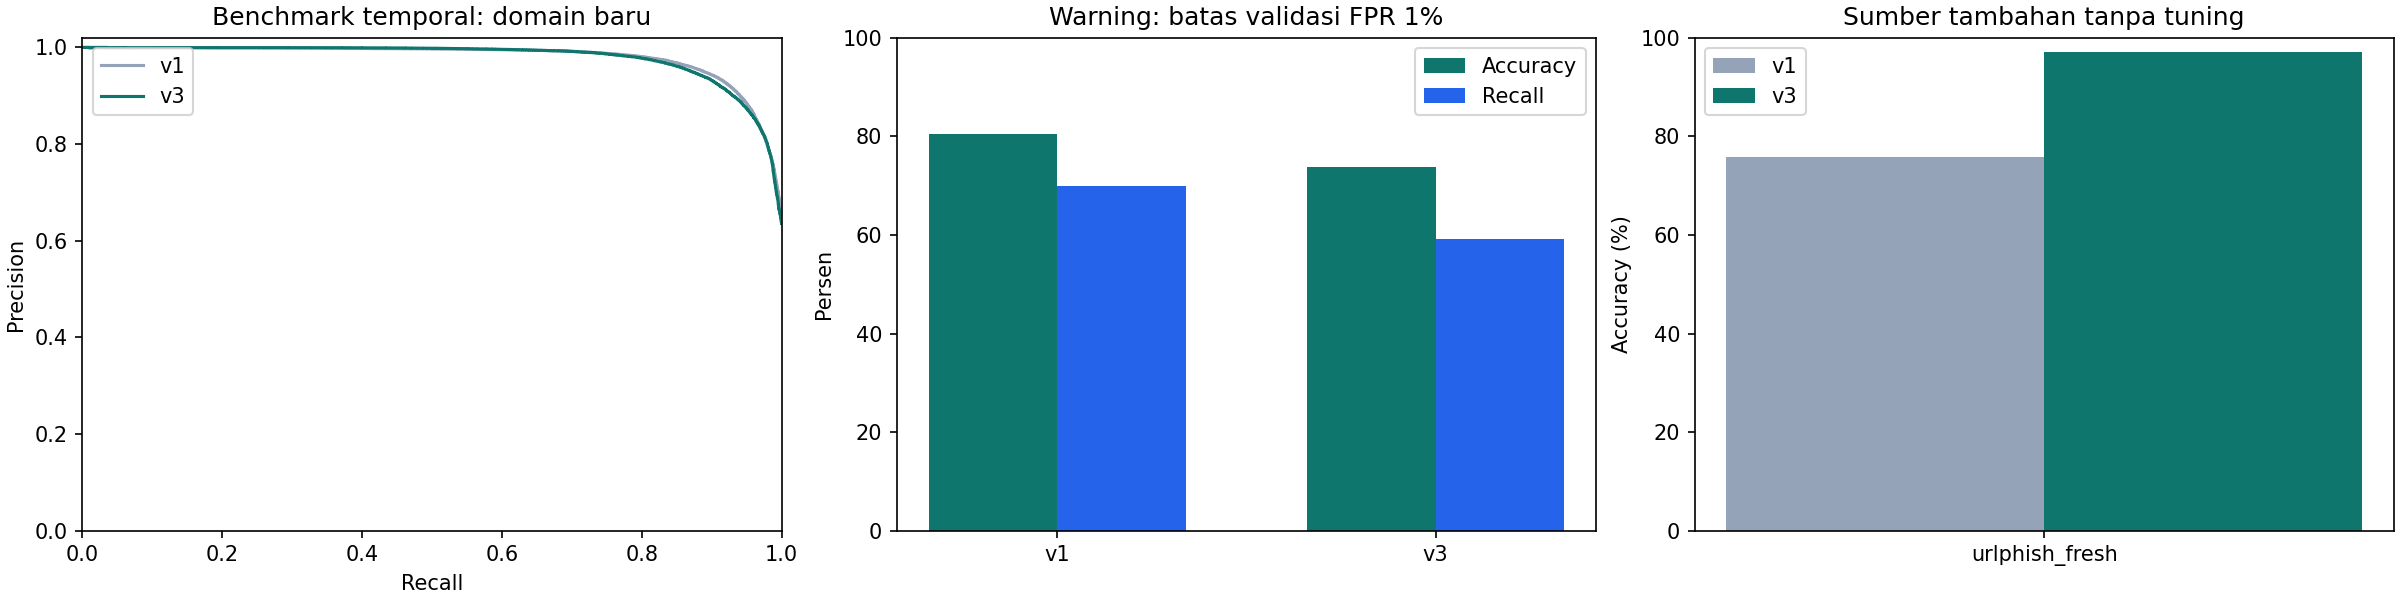

In [16]:
name = "observed_phresh_novel_domain"
data = datasets[name]
p_old, p_new = prediction_cache[name]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for label, prob, color in (("v1", p_old, "#94a3b8"), ("v3", p_new, "#0f766e")):
    precision, recall, _ = precision_recall_curve(data.label, prob)
    axes[0].plot(recall, precision, label=label, color=color)
axes[0].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Benchmark temporal: domain baru",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[0].legend()
comparison = results_table[
    (results_table.dataset == name) & (results_table.policy == "warning")
]
positions = np.arange(2)
axes[1].bar(
    positions - 0.17, comparison.accuracy, width=0.34, label="Accuracy", color="#0f766e"
)
axes[1].bar(
    positions + 0.17, comparison.recall, width=0.34, label="Recall", color="#2563eb"
)
axes[1].set(
    xticks=positions,
    xticklabels=comparison.model,
    ylim=(0, 100),
    title="Warning: batas validasi FPR 1%",
    ylabel="Persen",
)
axes[1].legend()
blind = results_table[
    results_table.dataset.isin(additional) & results_table.policy.eq("warning")
]
for index, (label, color) in enumerate((("v1", "#94a3b8"), ("v3", "#0f766e"))):
    part = blind[blind.model.eq(label)]
    axes[2].bar(
        np.arange(len(part)) + (index - 0.5) * 0.34,
        part.accuracy,
        width=0.34,
        label=label,
        color=color,
    )
axes[2].set(
    xticks=np.arange(len(additional)),
    xticklabels=list(additional),
    ylim=(0, 100),
    ylabel="Accuracy (%)",
    title="Sumber tambahan tanpa tuning",
)
axes[2].legend()
plot_path = RUN / "plots/evaluation-v3.png"
fig.savefig(plot_path, dpi=150)
plt.close(fig)
display(Image(filename=str(plot_path)))

## 12. Parity dan contoh URL/QR

Contoh sintetis saja. Model yang sama dipakai untuk URL dan hasil dekode QR. Raw query tidak menjadi fitur. LOW tetap bukan jaminan aman; konteks halaman, redirect, dan QRIS berada di luar model.


In [17]:
def predict_url(url, input_type="URL"):
    if input_type not in ("URL", "QR"):
        raise ValueError("invalid_input_type")
    prepared = prepare_url(url)
    probability = float(new_probability(bundle, [prepared.core])[0])
    risk = (
        "HIGH"
        if probability >= thresholds["high"]
        else ("MEDIUM" if probability >= thresholds["warning"] else "LOW")
    )
    return {
        "input_type": input_type,
        "target_redacted": prepared.core,
        "phishing_probability": probability,
        "risk_level": risk,
        "model": "Logistic Regression liblinear v3",
        "status": "research_candidate",
    }


synthetic = "https://example.org/login?email=person%40example.net"
direct, qr = predict_url(synthetic, "URL"), predict_url(synthetic, "QR")
assert direct["phishing_probability"] == qr["phishing_probability"]
assert (
    direct["phishing_probability"]
    == predict_url("https://example.org/login")["phishing_probability"]
)
assert "person" not in json.dumps(qr)
restored = joblib.load(MODEL_PATH)
assert np.array_equal(
    new_raw(bundle, ["https://example.org/login"]),
    new_raw(restored, ["https://example.org/login"]),
)
for source, data in additional.items():
    assert not set(data.group) & set(frame.group)
    assert not set(data.digest) & set(frame.digest)
assert sha256_file(MODEL_PATH) == frozen["bundle_sha256"]
display(pd.DataFrame([direct, qr]))
print(
    "Parity URL/QR, query, save/reload, checksum, dan isolasi domain sumber tambahan: lulus."
)
print("Artifact:", MODEL_PATH.relative_to(ROOT).as_posix())
assert (
    predict_url("http://example.org/login")["phishing_probability"]
    == predict_url("https://example.org/login")["phishing_probability"]
)

,input_type,target_redacted,phishing_probability,risk_level,model,status
0,URL,https://example.org/login,0.090265,LOW,Logistic Regression liblinear v3,research_candidate
1,QR,https://example.org/login,0.090265,LOW,Logistic Regression liblinear v3,research_candidate


Parity URL/QR, query, save/reload, checksum, dan isolasi domain sumber tambahan: lulus.
Artifact: ml/runs/notebook-tfidf-logistic-v3/artifacts/url-core-logistic-v3.joblib


## 13. Keputusan dan batas penggunaan

V2 tidak menggantikan baseline karena kenaikan benchmark tidak konsisten lintas sumber. V3 menggunakan sumber-sumber tersebut sebagai data pengembangan dan memperoleh challenge baru. Jangan menyebut hasil pada sumber yang sudah masuk pengembangan sebagai test independen.

Hitung keberhasilan dari keseluruhan hasil, termasuk FPR dan recall. Source cap tetap tidak menjamin FPR populasi baru. Dataset berumur lama, label sumber yang belum seluruhnya ditinjau manual, bias institusi, ketidaksesuaian angka katalog, dan tidak adanya gold set Indonesia membatasi klaim produksi.

Tidak ada URL target yang dibuka. Model tetap indikator Recognize; sandbox menangani proteksi saat membuka tautan dan Act tetap share card. Semua versi dan hasil negatif dipertahankan.


## 14. Analisis hasil aktual dan keputusan akhir

**Model v3:** Logistic Regression liblinear, C = 2.0, fitur karakter + token kata + 33 fitur struktur tanpa skema. Semua enam kandidat v3 konvergen. Fitting memakai **432.793 URL**: Phresh 302.812, PhiUSIIL 116.096, PhishVN core 9.769, Mendeley2020 4.116.

**Hasil tidak meningkat seragam.** V2 gagal generalisasi walaupun benchmark Phresh naik. V3 mengurangi salah peringatan lintas sumber melalui data yang lebih beragam dan threshold yang dibatasi per sumber, dengan pengorbanan recall pada sebagian benchmark. Tidak ada penggantian model produksi otomatis.

### Perbandingan kebijakan peringatan

Angka berikut memakai kebijakan warning model masing-masing yang dipilih dari partisi threshold. V1 membatasi FPR pada sumber Phresh; v3 membatasi FPR pada setiap sumber pengembangan. Target validasi sama-sama 1%, tetapi batas per sumber v3 lebih ketat. Tidak ada penyesuaian threshold dari hasil test.

| Evaluasi | N | Accuracy v1 | Accuracy v3 | Recall v3 | FPR v3 | Balanced accuracy v3 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Phresh domain baru (benchmark teramati) | 80,052 | 80.48% | 73.85% | 59.10% | 0.38% | 79.36% |
| Mendeley group holdout (sumber pengembangan) | 1,002 | 47.01% | 81.54% | 73.93% | 0.99% | 86.47% |
| PhishVN group holdout (sumber pengembangan) | 2,123 | 81.39% | 93.45% | 49.14% | 1.11% | 74.01% |
| PhiUSIIL group holdout (sumber pengembangan) | 20,219 | 83.98% | 75.93% | 41.33% | 0.05% | 70.64% |
| URL-Phish (challenge baru) | 85,824 | 75.87% | 97.09% | 64.01% | 0.44% | 81.79% |

Rata-rata **deskriptif dengan bobot setara untuk lima sumber**: accuracy 73.75% -> 84.37%; balanced accuracy 71.44% -> 78.45%; recall 54.35% -> 57.50%; FPR 11.47% -> 0.60%. Rata-rata ini bukan estimasi accuracy trafik pengguna dan empat benchmark/sumber sudah pernah diamati atau masuk pengembangan. Jangan membandingkannya langsung dengan angka 80,48% dari satu benchmark lama.

### Bukti ketidakpastian dan keterbatasan

- Pada Phresh domain baru, accuracy v3 turun 6,63 poin persentase; CI95 perubahan berpasangan per domain sekitar **-7,76 hingga -5,46 poin**. Penurunan ini nyata dalam sampel tersebut dan tidak boleh disembunyikan.
- Pada challenge URL-Phish, accuracy naik sekitar 21,21 poin; CI95 perubahan sekitar **+20,87 hingga +21,58 poin**. Kenaikan terutama berasal dari turunnya false positive, sedangkan kenaikan recall kecil dan intervalnya melintasi nol.
- Challenge memiliki 79.866 benign dan 5.958 phishing. Menebak semua benign saja memperoleh 93,06% accuracy. V3 mencapai 97,09%, tetapi balanced accuracy hanya 81,78% dan recall sekitar 64,01%. Jadi angka 97,09% tidak berarti semua phishing tertangkap.
- Selisih katalog URL-Phish tidak selesai hanya dengan deduplikasi: aset memiliki 116.600 baris, 115.231 URL mentah unik, 1.369 duplikat persis, tanpa konflik label pada URL persis. Deskripsi menyebut 111.660 URL unik. Dataset tetap diperlakukan sebagai challenge yang berlabel menurut pemilik, bukan gold terverifikasi manual.
- Negatif URL-Phish banyak berasal dari institusi/homepage; PhishVN memiliki keterbatasan audit label; PhiUSIIL tidak memiliki timestamp observasi per baris. Tidak satu pun menggantikan gold set Indonesia yang ditinjau manual.

### Diagnosis threshold tetap 0,5

Diagnosis sekunder p >= 0,5 ditetapkan sebelum challenge diprediksi dan tidak dipakai memilih model. Ini membedakan keputusan biner biasa dari kebijakan warning yang sengaja konservatif. Jangan mencampurkan metrik dua kebijakan.

| Evaluasi | Accuracy v1 @0,5 | Accuracy v3 @0,5 | Recall v3 @0,5 | FPR v3 @0,5 |
| --- | ---: | ---: | ---: | ---: |
| Phresh domain baru (benchmark teramati) | 90.32% | 89.10% | 87.91% | 8.82% |
| URL-Phish (challenge baru) | 42.79% | 88.05% | 92.53% | 12.29% |

Contoh penghitungan ulang diagnosis setelah Run All (tidak melakukan fitting):

```python
data = datasets["urlphish_fresh"]
metrics(data.label, new_probability(bundle, data.core), 0.5)
```

**Keputusan:** v3 adalah kandidat riset dengan jangkauan sumber lebih luas dan false positive lebih rendah, tetapi belum terbukti menjadi pengganti yang lebih baik untuk seluruh kasus. Baseline dan v2 dipertahankan untuk perbandingan. Prioritas sebelum produksi adalah gold set Indonesia dengan label independen, hard negatives realistis, data waktu terbaru, serta pemilihan biaya false positive/false negative yang sesuai penggunaan. URL-only tetap terbatas untuk situs sah yang disusupi, query-only threats, dan shortlink.
